In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()

In [21]:
df = pd.read_csv(r"C:\ml-pipeline\data\raw\WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [22]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [23]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


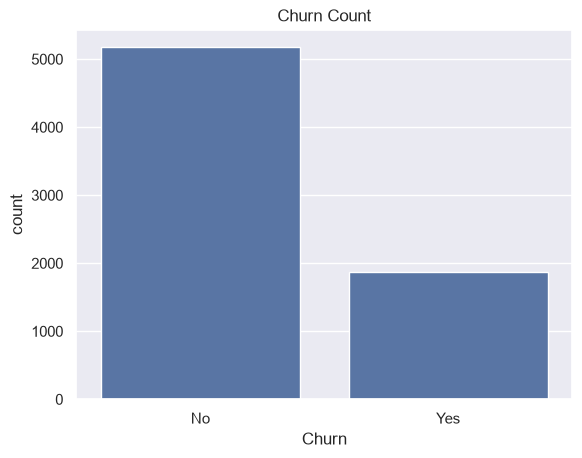

In [24]:
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True))

sns.countplot(x="Churn", data=df)
plt.title("Churn Count")
plt.show()

Churn             No   Yes
Contract                  
Month-to-month  2220  1655
One year        1307   166
Two year        1647    48


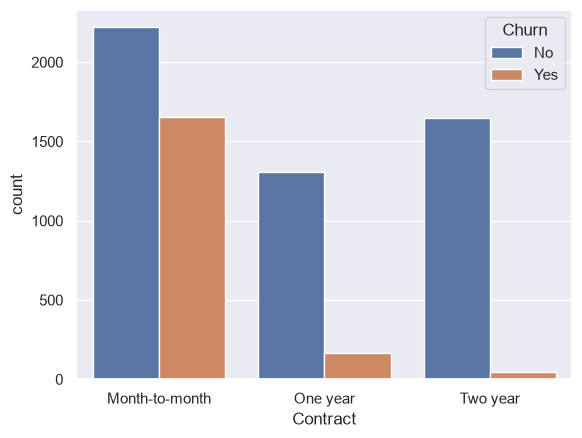

In [25]:
print(pd.crosstab(df["Contract"], df["Churn"]))
sns.countplot(x="Contract", hue="Churn", data=df)
plt.show()

Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64


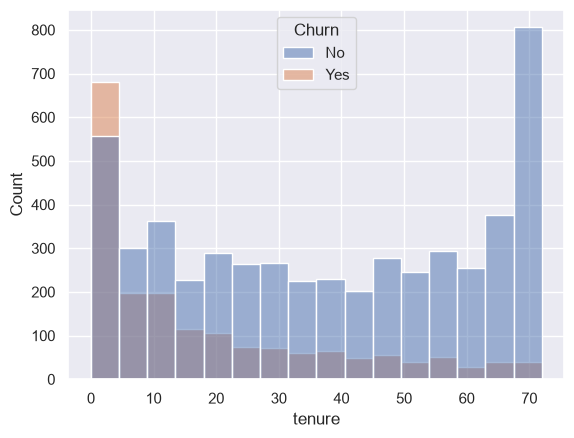

In [26]:
print(df.groupby("Churn")["tenure"].mean())
sns.histplot(x="tenure", hue="Churn", data=df)
plt.show()

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64


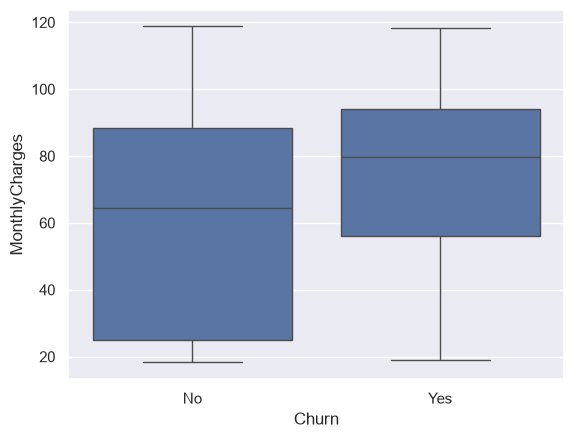

In [27]:
print(df.groupby("Churn")["MonthlyCharges"].mean())
sns.boxplot(x="Churn", y="MonthlyCharges", data=df)
plt.show()

                 tenure  MonthlyCharges  TotalCharges
tenure          1.00000        0.247900      0.825880
MonthlyCharges  0.24790        1.000000      0.651065
TotalCharges    0.82588        0.651065      1.000000


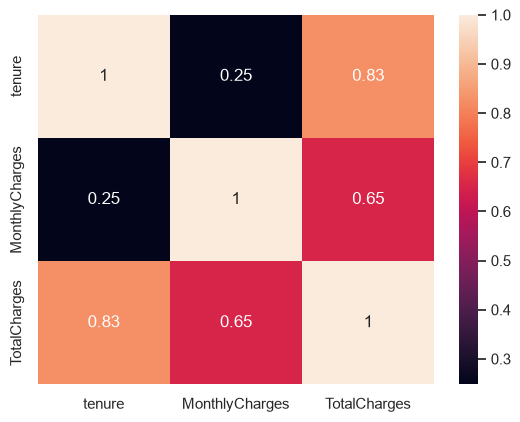

In [28]:
numeric_cols = df[["tenure", "MonthlyCharges", "TotalCharges"]]
print(numeric_cols.corr())
sns.heatmap(numeric_cols.corr(), annot=True)
plt.show()

## Key Insights
- 7043 customers, 21 columns. 26.5% ne churn kiya (class imbalance).
- TotalCharges mein 11 missing values thi, number mein convert karke handle ki.
- Month-to-month contract: 1655 churn, Two year: sirf 48.
- Churn karne walon ka average tenure 18 mahine, na karne walon ka 38 mahine.
- Churn karne walon ka average monthly bill 74, na karne walon ka 61.

In [29]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

df_model = df.drop("customerID", axis=1)
df_model["Churn"] = df_model["Churn"].map({"No": 0, "Yes": 1})

X = df_model.drop("Churn", axis=1)
y = df_model["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

num_cols = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in X.columns if c not in num_cols]

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

print(X_train.shape, X_test.shape)

(5634, 19) (1409, 19)


In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

def train_and_score(name, model):
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    return {
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, pred), 3),
        "Precision": round(precision_score(y_test, pred), 3),
        "Recall": round(recall_score(y_test, pred), 3),
        "F1": round(f1_score(y_test, pred), 3),
        "ROC-AUC": round(roc_auc_score(y_test, proba), 3),
    }

In [31]:
results = []

results.append(train_and_score(
    "Logistic Regression",
    LogisticRegression(max_iter=1000, class_weight="balanced")))

results.append(train_and_score(
    "Random Forest",
    RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42)))

ratio = (y_train == 0).sum() / (y_train == 1).sum()
results.append(train_and_score(
    "XGBoost",
    XGBClassifier(n_estimators=200, scale_pos_weight=ratio, random_state=42)))

pd.DataFrame(results)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.738,0.504,0.783,0.614,0.841
1,Random Forest,0.764,0.548,0.620,0.582,0.822
2,XGBoost,0.752,0.528,0.599,0.561,0.806


## Model Comparison

**Goal:** Predict whether a customer will churn, and choose the best model for the job.

**Models tried:**
- Logistic Regression
- Random Forest
- XGBoost

**Handling class imbalance:** Only about 27% of customers churned, so I used `class_weight="balanced"` for Logistic Regression and Random Forest, and `scale_pos_weight` for XGBoost. This makes the models pay more attention to the churn class.

**Metrics used:** Accuracy alone can be misleading on imbalanced data, so I also tracked Precision, Recall, F1 and ROC-AUC.

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Logistic Regression | 0.738 | 0.504 | 0.783 | 0.614 | 0.841 |
| Random Forest | 0.764 | 0.548 | 0.620 | 0.582 | 0.822 |
| XGBoost | 0.752 | 0.528 | 0.599 | 0.561 | 0.806 |

**Result:** Logistic Regression performed best, with the highest ROC-AUC (0.841) and the highest Recall (0.783). Random Forest and XGBoost had slightly higher accuracy but missed more churners.

**Why Logistic Regression:** In a churn problem, missing a customer who is about to leave costs more than a false alarm, so Recall and ROC-AUC matter more than accuracy. It is also simple and easy to explain.

In [32]:
from sklearn.model_selection import GridSearchCV

pipe = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))
])

params = {"model__C": [0.01, 0.1, 1, 10]}

grid = GridSearchCV(pipe, params, scoring="roc_auc", cv=5)
grid.fit(X_train, y_train)

print("Best C:", grid.best_params_)
print("CV ROC-AUC:", round(grid.best_score_, 3))

Best C: {'model__C': 10}
CV ROC-AUC: 0.845


In [33]:
best_model = grid.best_estimator_

pred = best_model.predict(X_test)
proba = best_model.predict_proba(X_test)[:, 1]

print("Accuracy :", round(accuracy_score(y_test, pred), 3))
print("Precision:", round(precision_score(y_test, pred), 3))
print("Recall   :", round(recall_score(y_test, pred), 3))
print("F1       :", round(f1_score(y_test, pred), 3))
print("ROC-AUC  :", round(roc_auc_score(y_test, proba), 3))

Accuracy : 0.74
Precision: 0.506
Recall   : 0.783
F1       : 0.615
ROC-AUC  : 0.841


In [34]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_test, pred))

[[749 286]
 [ 81 293]]


In [35]:
import joblib

joblib.dump(best_model, r"C:\ml-pipeline\models\churn_model.joblib")
print("Model is saved!")

Model is saved!


## Final Model

- **Best model:** Logistic Regression with `class_weight="balanced"`, tuned using GridSearchCV (5-fold cross-validation) over the regularization strength C.
- **Test performance:** ROC-AUC 0.841, Recall 0.783, Precision 0.506, F1 0.615.
- **Confusion matrix:** Out of 374 customers who actually churned, the model caught 293 and missed 81. It raised 286 false alarms.
- **Takeaway:** Tuning gave only a small improvement (CV ROC-AUC 0.8453 to 0.8455), so I kept the simple model. Recall was prioritised because missing a churner costs more than a false alarm.
- **Saved model:** `models/churn_model.joblib` (preprocessing and model together in one pipeline).

In [36]:
import mlflow

mlflow.set_tracking_uri("sqlite:///C:/ml-pipeline/mlflow.db")
mlflow.set_experiment("churn-prediction")

2026/10/26 01:38:37 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/26 01:38:37 INFO mlflow.store.db.utils: Updating database tables
2026/10/26 01:38:41 INFO mlflow.tracking.fluent: Experiment with name 'churn-prediction' does not exist. Creating a new experiment.


<Experiment: artifact_location='file:c:/ml-pipeline/notebooks/mlruns/1', creation_time=1792958921681, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1792958921681, lifecycle_stage='active', name='churn-prediction', tags={}, trace_location=None, workspace='default'>

In [37]:
runs = [
    ("Logistic Regression",
     LogisticRegression(max_iter=1000, class_weight="balanced"),
     {"model": "LogisticRegression", "class_weight": "balanced"}),

    ("Random Forest",
     RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42),
     {"model": "RandomForest", "n_estimators": 200, "class_weight": "balanced"}),

    ("XGBoost",
     XGBClassifier(n_estimators=200, scale_pos_weight=ratio, random_state=42),
     {"model": "XGBoost", "n_estimators": 200, "scale_pos_weight": round(float(ratio), 2)}),
]

for name, model, params in runs:
    with mlflow.start_run(run_name=name):
        scores = train_and_score(name, model)
        mlflow.log_params(params)
        mlflow.log_metric("accuracy", scores["Accuracy"])
        mlflow.log_metric("precision", scores["Precision"])
        mlflow.log_metric("recall", scores["Recall"])
        mlflow.log_metric("f1", scores["F1"])
        mlflow.log_metric("roc_auc", scores["ROC-AUC"])
        print(name, "logged")

Logistic Regression logged
Random Forest logged
XGBoost logged
